# EUR/USD: volatility clustering, ARCH and GARCH

Study dependence in daily exchange-rate movements and model their changing
conditional variance. Compare AR models of signed and squared log changes,
derive Gaussian ARCH(1) kurtosis, and estimate ARCH/GARCH models using AIC and
BIC. Compare fitted volatility with rolling and EWMA measures, then produce
one- and two-step volatility forecasts.

The analysis uses **1,249 published quotation dates in 2021-2025**. Data are
included locally; no live data download or API key is required.

Data Sources:

- [Federal Reserve Board, H.10 historical euro rates](https://www.federalreserve.gov/releases/h10/hist/dat00_eu.htm):
  daily New York noon buying rates, in **US dollars per euro**, not seasonally adjusted.
- [FRED DEXUSEU](https://fred.stlouisfed.org/series/DEXUSEU): equivalent series and definition.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
import importlib.util
import subprocess
import sys

# Install the additional volatility-model library only when missing.
if importlib.util.find_spec("arch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "arch>=8.0,<9"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.stats.diagnostic import het_arch
from arch import arch_model
from arch.univariate import Normal
from IPython.display import display

## Data

In [3]:
levels = pd.read_csv(DATA_DIR / "daily_eur_usd.csv", index_col="date", parse_dates=True)
if not levels.index.is_unique or not levels.index.is_monotonic_increasing:
    raise ValueError("Inspect duplicate or unordered quotation dates.")
if levels.isna().any().any() or not levels["usd_per_eur"].gt(0).all():
    raise ValueError("Inspect missing or non-positive exchange rates.")
display(levels.head().round(4))

,usd_per_eur
date,
2009-12-01,1.5100
2009-12-02,1.5059
2009-12-03,1.5081
2009-12-04,1.4885
2009-12-07,1.4820


## Log changes and squared demeaned changes

For exchange-rate quote $S_t$ in US dollars per euro, define

$$r_t=100\log(S_t/S_{t-1}),\qquad q_t=(r_t-\bar r)^2.$$

A positive change means that the euro appreciates against the dollar. This is
the percentage log change in the exchange-rate quotation; it is not an
interest-inclusive investment return. Dates with no published quotation are
omitted, without interpolation, forward filling or inserted zero changes.
A lag denotes one observed quotation, which may span several calendar days.

The quantity $q_t$ measures squared movement size in squared percentage-point
units. It is a noisy proxy for conditional variance when the conditional mean
is sufficiently close to zero, rather than volatility (the conditional standard
deviation) itself. Subtracting the full-sample mean is descriptive and does not
estimate a time-varying conditional mean.

In [4]:
all_changes = 100 * np.log(levels["usd_per_eur"]).diff()
returns = all_changes.loc["2021":"2025"].rename("FX log change")
if returns.isna().any() or returns.empty:
    raise ValueError("Missing analysis changes: inspect the quotation base.")
squared_returns = ((returns - returns.mean()) ** 2).rename("Squared demeaned change")
series = {"FX log changes": returns, "Squared demeaned changes": squared_returns}
print(f"Sample: {len(returns)} quotations, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")
display(pd.concat([returns, squared_returns], axis=1).head().round(4))

Sample: 1249 quotations, 2021-01-04 to 2025-12-31


,FX log change,Squared demeaned change
date,,
2021-01-04,0.1960,0.0397
2021-01-05,0.3340,0.1138
2021-01-06,-0.0407,0.0014
2021-01-07,-0.2036,0.0401
2021-01-08,-0.1060,0.0106


## Exchange-rate changes and movement magnitudes

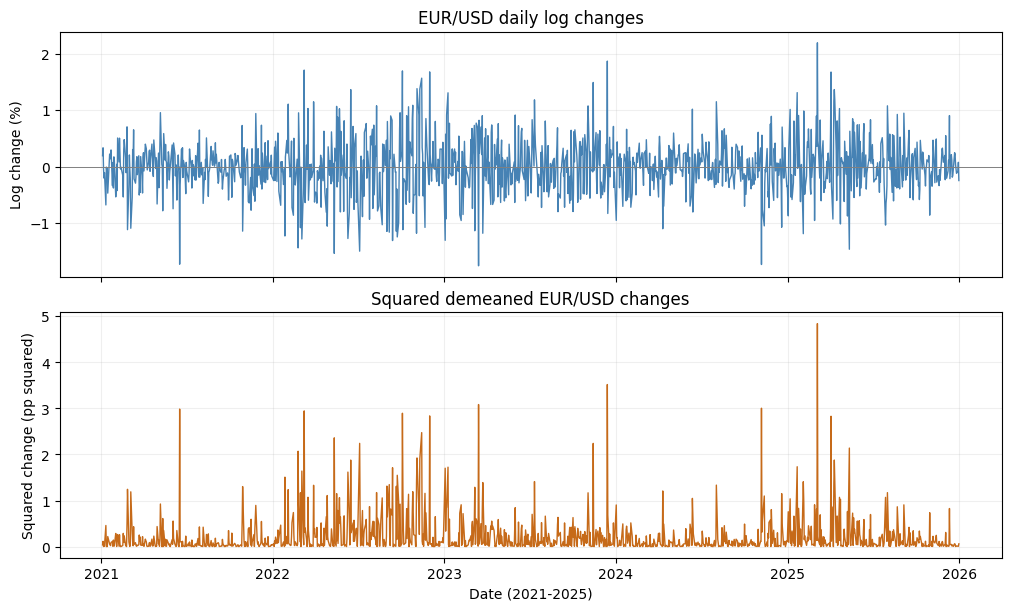

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
for ax, values, title, unit, color in zip(
    axes, [returns, squared_returns], ["EUR/USD daily log changes", "Squared demeaned EUR/USD changes"],
    ["Log change (%)", "Squared change (pp squared)"], ["steelblue", "#C66A19"]
):
    ax.plot(values.index, values, color=color, linewidth=1)
    ax.set(title=title, ylabel=unit)
    ax.grid(alpha=0.2)
axes[0].axhline(0, color="grey", linewidth=0.7)
axes[1].set_xlabel("Date (2021-2025)")
plt.show()

Large appreciations and depreciations can cluster even when the signed changes
have little autocorrelation. Squaring removes the sign and highlights those
periods. A single large squared change is not the conditional variance itself.

## The distribution of daily changes

Compare the empirical distribution with a Normal density fitted using the
sample mean and standard deviation. Sample excess kurtosis describes this
unconditional distribution; it is different from the distribution of shocks
conditional on past information.

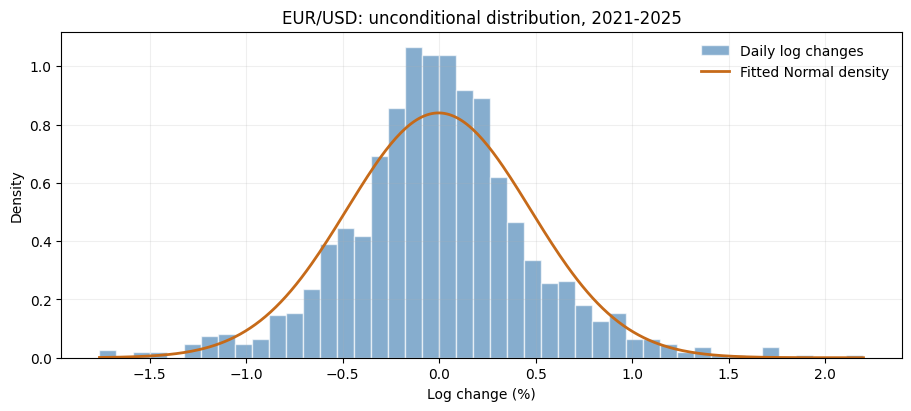

,Sample moment
Mean (%),-0.0033
Sample SD (%),0.4750
Skewness,0.1501
Excess kurtosis,1.5934


In [6]:
grid = np.linspace(returns.min(), returns.max(), 300)
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.hist(returns, bins=45, density=True, alpha=0.65, color="steelblue", edgecolor="white", label="Daily log changes")
ax.plot(grid, stats.norm.pdf(grid, loc=returns.mean(), scale=returns.std(ddof=1)),
        color="#C66A19", linewidth=2, label="Fitted Normal density")
ax.set(xlabel="Log change (%)", ylabel="Density", title="EUR/USD: unconditional distribution, 2021-2025")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()
display(pd.Series({"Mean (%)": returns.mean(), "Sample SD (%)": returns.std(ddof=1),
                   "Skewness": stats.skew(returns, bias=False),
                   "Excess kurtosis": stats.kurtosis(returns, fisher=True, bias=False)}, name="Sample moment").round(4).to_frame())

## Autocorrelations

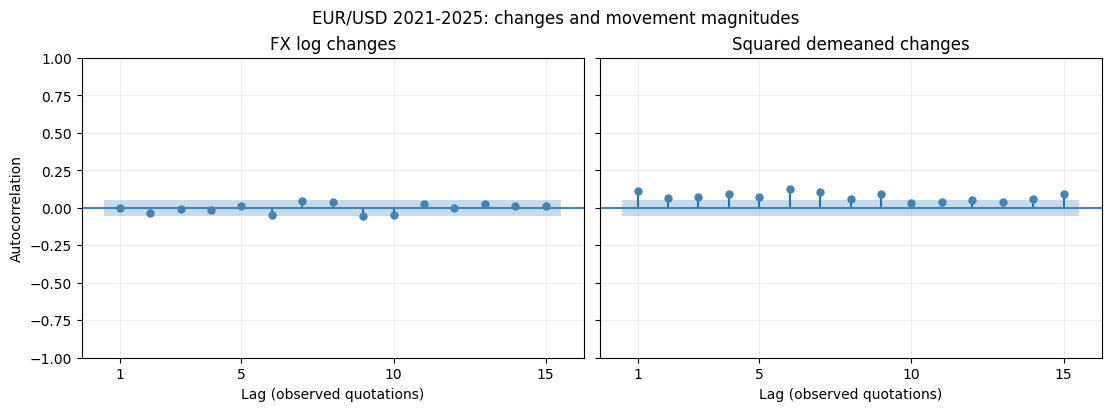

In [7]:
MAX_ACF_LAG = 15
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, (name, values) in zip(axes, series.items()):
    plot_acf(values, lags=MAX_ACF_LAG, zero=False, alpha=0.05,
             bartlett_confint=False, ax=ax, color="steelblue")
    ax.set(title=name, xlabel="Lag (observed quotations)")
    ax.set_xticks([1, 5, 10, 15])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("EUR/USD 2021-2025: changes and movement magnitudes")
plt.show()

The squared-change ACF can reveal dependence in movement magnitudes that is
not apparent in signed changes. The shaded bands are approximate, pointwise
white-noise reference bands, not simultaneous bounds. Changing volatility can
affect their calibration; they are descriptive rather than definitive tests.

## Autoregressions and lag selection

For each series $z_t\in\{r_t,q_t\}$, estimate

$$z_t=c+\phi_1z_{t-1}+\cdots+\phi_pz_{t-p}+e_t.$$

Compare **contiguous AR orders 0-10** with an intercept. All candidates use
`hold_back=10`, so they share the same **1,239 dependent-variable observations**.
AR(0) contains only the intercept. Minimise AIC and BIC separately for each
series, retaining the same common sample for all reported estimates.

Both criteria balance fit and parameter count. With maximised conditional
log likelihood $\ell$ and $K$ estimated parameters (including innovation variance),

$$AIC=-2\ell+2K,\qquad BIC=-2\ell+K\log n.$$

Here $n=1,239$, so BIC penalises each extra parameter more than AIC and may
choose a shorter model. Compare its values across candidate orders
for the **same dependent variable**; their numerical levels are not comparable
between changes and squared changes, which have different units and distributions.
The Gaussian conditional likelihood underlying these criteria is a working approximation here.

In [8]:
MAX_AR_LAG = 10
CRITERIA = ["AIC", "BIC"]
models, rows = {}, []
for name, values in series.items():
    models[name] = {}
    for p in range(MAX_AR_LAG + 1):
        fit = AutoReg(values.to_numpy(), lags=p, trend="c", hold_back=MAX_AR_LAG).fit()
        models[name][p] = fit
        rows.append({"Series": name, "AR order": p, "AIC": fit.aic, "BIC": fit.bic,
                     "Estimation n": int(fit.nobs)})
selection = pd.DataFrame(rows)
selected_orders = pd.DataFrame({
    criterion: {name: min(fits, key=lambda p: getattr(fits[p], criterion.lower()))
                for name, fits in models.items()} for criterion in CRITERIA
})
selected_orders.index.name = "Series"
display(selection.pivot(index="AR order", columns="Series", values=CRITERIA).round(3))
display(selected_orders.rename_axis(columns="Criterion: selected AR order"))

AIC                                     BIC  \
Series   FX log changes Squared demeaned changes FX log changes   
AR order                                                          
0              1680.404                 1417.384       1690.648   
1              1682.403                 1404.107       1697.769   
2              1682.855                 1402.466       1703.344   
3              1684.732                 1399.541       1710.342   
4              1686.514                 1394.226       1717.246   
5              1688.390                 1393.455       1724.244   
6              1687.463                 1382.470       1728.439   
7              1686.835                 1378.144       1732.934   
8              1686.928                 1379.609       1738.149   
9              1685.516                 1377.034       1741.859   
10             1684.612                 1378.953       1746.076   

                                   
Series   Squared demeaned changes  
AR order                           
0                        1427.628  
1                        1419.473  
2                        1422.954  
3                        1425.152  
4                        1424.958  
5                        1429.309  
6                        1423.447  
7                        1424.243  
8                        1430.830  
9                        1433.377  
10                       1440.417

Criterion: selected AR order,AIC,BIC
Series,,
FX log changes,0,0
Squared demeaned changes,9,1


## Selected-model estimates

In [9]:
# Estimate each distinct selected model once, with the same dependent-variable sample.
HAC_LAGS = 5
selected_fits, rows = {}, []
for name, values in series.items():
    for p in sorted(set(selected_orders.loc[name])):
        criteria = ", ".join(c for c in CRITERIA if selected_orders.loc[name, c] == p)
        fit = AutoReg(values.to_numpy(), lags=p, trend="c", hold_back=MAX_AR_LAG).fit(
            cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS, "use_correction": True}, use_t=True)
        selected_fits[(name, p)] = fit
        interval = np.asarray(fit.conf_int())
        for j, term in enumerate(["Intercept"] + [f"Lag {lag}" for lag in range(1, p + 1)]):
            rows.append({"Series": name, "Model": f"AR({p}) ({criteria})", "Term": term,
                         "Estimate": fit.params[j], "HAC SE": fit.bse[j], "p-value": fit.pvalues[j],
                         "95% lower": interval[j, 0], "95% upper": interval[j, 1]})
coefficients = pd.DataFrame(rows).set_index(["Series", "Model", "Term"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(coefficients)

Estimate  HAC SE  \
Series                   Model            Term                          
FX log changes           AR(0) (AIC, BIC) Intercept -0.002459  0.0131   
Squared demeaned changes AR(1) (BIC)      Intercept    0.2014 0.01532   
                                          Lag 1        0.1107 0.03474   
                         AR(9) (AIC)      Intercept    0.1202 0.01815   
                                          Lag 1       0.07803 0.02969   
                                          Lag 2       0.02507 0.02672   
                                          Lag 3       0.03642 0.03218   
                                          Lag 4       0.06119 0.03484   
                                          Lag 5       0.03077 0.03554   
                                          Lag 6       0.09271  0.0341   
                                          Lag 7       0.06794 0.03667   
                                          Lag 8       0.01602 0.02633   
                                          Lag 9        0.0607 0.03193   

                                                      p-value  95% lower  \
Series                   Model            Term                             
FX log changes           AR(0) (AIC, BIC) Intercept    0.8512   -0.02817   
Squared demeaned changes AR(1) (BIC)      Intercept 4.642e-37     0.1714   
                                          Lag 1      0.001473    0.04256   
                         AR(9) (AIC)      Intercept 5.339e-11    0.08457   
                                          Lag 1        0.0087    0.01977   
                                          Lag 2        0.3483   -0.02736   
                                          Lag 3        0.2579   -0.02671   
                                          Lag 4       0.07931  -0.007169   
                                          Lag 5        0.3868   -0.03896   
                                          Lag 6      0.006651     0.0258   
                                          Lag 7       0.06416  -0.004003   
                                          Lag 8        0.5431   -0.03564   
                                          Lag 9        0.0575  -0.001936   

                                                     95% upper  
Series                   Model            Term                  
FX log changes           AR(0) (AIC, BIC) Intercept    0.02325  
Squared demeaned changes AR(1) (BIC)      Intercept     0.2315  
                                          Lag 1         0.1789  
                         AR(9) (AIC)      Intercept     0.1558  
                                          Lag 1         0.1363  
                                          Lag 2         0.0775  
                                          Lag 3        0.09954  
                                          Lag 4         0.1295  
                                          Lag 5         0.1005  
                                          Lag 6         0.1596  
                                          Lag 7         0.1399  
                                          Lag 8        0.06767  
                                          Lag 9         0.1233

For this frozen sample, **AIC and BIC both select AR(0) for FX log changes**.
For squared demeaned changes, **AIC selects AR(9), while BIC selects AR(1)**.
The more heavily penalised BIC favours a shorter description of magnitude
dependence. Neither choice identifies a uniquely correct population order;
compare the selected models' coefficients and uncertainty.

Information-criterion selection does not imply that every included coefficient
is statistically significant. In the AIC-selected AR(9), only lags 1 and 6
are significant at 5% with the reported HAC standard errors. Individual tests
also condition on a model selected using these same data.

The squared-change intercept is measured in squared percentage-point units;
its autoregressive coefficients are unitless. The tables test coefficients
against zero. HAC standard errors use five observed-quotation lags, Bartlett
weights and a finite-sample correction; the t reference is approximate.
These intervals condition on the selected model and do not account for order
selection. HAC does not correct an unsuitable conditional-mean model or
endogenous regressors.

## Interpreting the comparison

AR(0) selection does not prove white noise, independence, a random-walk exchange
rate or market efficiency. It says only that neither criterion favours lagged
signed changes among these candidates on this sample. Both criteria favour
some dependence in squared changes, consistent with volatility clustering;
this does not establish profitable currency forecasts.

The squared-change AR is an illustrative linear model of a noisy variance proxy.
It is not constrained to give nonnegative variance forecasts. The following
sections instead model conditional variance directly using ARCH and GARCH.
In-sample fit does not establish out-of-sample forecast accuracy.

## Gaussian ARCH(1): conditional and unconditional moments

Write the log change as $r_t=\mu+\epsilon_t$, with

$$\epsilon_t=\sigma_t z_t,\qquad z_t\stackrel{iid}{\sim}N(0,1),\qquad
\sigma_t^2=\omega+\alpha\epsilon_{t-1}^2.$$

The shock $z_t$ is independent of past information. Assume $\omega>0$ and
$\alpha\ge0$ for positive conditional variance. For a stationary solution with
finite second moment, iterated expectations give

$$m_2=E[\epsilon_t^2]=E[\sigma_t^2]=\omega+\alpha m_2
\quad\Longrightarrow\quad m_2=\frac{\omega}{1-\alpha},\qquad \alpha<1.$$

Gaussian shocks have $E[z_t^4]=3$. If the stationary fourth moment exists,

$$m_4=E[\epsilon_t^4]=3E[\sigma_t^4]
=3\omega^2+6\omega\alpha m_2+3\alpha^2m_4,$$

so

$$m_4=\frac{3\omega^2(1+\alpha)}{(1-\alpha)(1-3\alpha^2)},\qquad
\kappa=\frac{m_4}{m_2^2}=3\frac{1-\alpha^2}{1-3\alpha^2}.$$

Finite kurtosis therefore requires the **stronger condition**
$3\alpha^2<1$, or $0\le\alpha<1/\sqrt3$. For
$1/\sqrt3\le\alpha<1$, the stationary model can have finite variance but no
finite fourth moment. At $\alpha=0$, kurtosis is 3; at a positive $\alpha$
within the fourth-moment region it exceeds 3. Thus Gaussian **conditional**
shocks can generate an unconditionally leptokurtic distribution. Excess
kurtosis is $\kappa-3$, not $\kappa$ itself.

## Testing for ARCH effects

Start with a constant conditional-mean model and residuals
$\widehat\epsilon_t=r_t-\bar r$. Use **10 lags**, chosen before inspecting
the test result, in the auxiliary regression of squared residuals on a
constant and their lagged squares. Test

$$H_0:\gamma_1=\cdots=\gamma_{10}=0,\qquad
H_1:\text{at least one lag coefficient differs from zero}.$$

The ARCH LM statistic is approximately $\chi^2_{10}$ under its usual null
assumptions. Allow one fitted mean parameter in the degrees-of-freedom
correction. Rejection indicates ARCH-type dependence at these lags, not
which GARCH order or innovation distribution is correct.

In [10]:
ARCH_TEST_LAGS = 10
mean_residuals = returns - returns.mean()
lm_stat, lm_pvalue, _, _ = het_arch(mean_residuals, nlags=ARCH_TEST_LAGS, ddof=1)
arch_test = pd.DataFrame({"LM statistic": [lm_stat], "Reference df": [ARCH_TEST_LAGS],
                          "p-value": [lm_pvalue],
                          "Decision at 5%": ["Reject H0" if lm_pvalue < 0.05 else "Do not reject H0"]},
                         index=["Constant-mean residuals"])
display(arch_test.style.format({"LM statistic": "{:.4f}", "p-value": "{:.3g}"}))

,LM statistic,Reference df,p-value,Decision at 5%
Constant-mean residuals,57.0291,10,1.32e-08,Reject H0


The p-value is about **1.32e-8**, so reject the joint null at 5% for these
data. This motivates modelling conditional variance, while preserving the
distinction between dependence in movement magnitudes and predictability of
the sign of a currency movement.

## ARCH and GARCH estimation

Use the same constant-mean specification and Gaussian conditional likelihood
for all candidates:

$$r_t=\mu+\epsilon_t,\qquad
\sigma_t^2=\omega+\sum_{i=1}^{p}\alpha_i\epsilon_{t-i}^2
+\sum_{j=1}^{q}\beta_j\sigma_{t-j}^2.$$

Here **$p$ counts squared-shock lags and $q$ counts variance lags**, matching
the `arch` library convention. ARCH(1) is $(p,q)=(1,0)$. Compare constant
variance, ARCH(1), ARCH(2), and GARCH orders (1,1), (1,2), (2,1), (2,2).
Both information criteria use the same **1,249 observations**, response scale,
mean specification and Gaussian likelihood. These likelihood values are not
comparable with those from the earlier regressions on squared changes.

Changes are already in percent and are not multiplied by 100 again. A fitted
conditional standard deviation of 0.5 means 0.5 percentage points of daily
log change. Initialise the variance recursion using the last 50 quotations
before 2021, and hold that initial value fixed across candidates. Check the
optimiser status rather than silently discarding unsuccessful fits.

The library imposes nonnegative variance coefficients. Finite unconditional
variance requires $\sum\alpha_i+\sum\beta_j<1$, in which case it is
$\omega/(1-\sum\alpha_i-\sum\beta_j)$. This is a second-moment condition;
it does not by itself establish a finite fourth moment.

In [11]:
PRE_SAMPLE_LENGTH = 50
pre_sample = all_changes.loc[:"2020-12-31"].dropna().tail(PRE_SAMPLE_LENGTH)
BACKCAST = float(pre_sample.var(ddof=0))
VARIANCE_ORDERS = [(0, 0), (1, 0), (2, 0), (1, 1), (1, 2), (2, 1), (2, 2)]

def model_label(order):
    p, q = order
    return "Constant variance" if p == 0 else f"ARCH({p})" if q == 0 else f"GARCH({p},{q})"

def fit_variance_model(values, order, initial_variance=BACKCAST, starting_values=None):
    p, q = order
    model = arch_model(values, mean="Constant", vol="Constant" if p == 0 else "GARCH",
                       p=max(1, p), q=q, dist="normal", rescale=False, hold_back=0)
    result = model.fit(disp="off", update_freq=0, cov_type="robust", backcast=initial_variance,
                       starting_values=starting_values, show_warning=False,
                       options={"maxiter": 2000, "ftol": 1e-9})
    if result.convergence_flag != 0:
        raise RuntimeError(str(result.optimization_result.message))
    return result

variance_fits, rows = {}, []
for order in VARIANCE_ORDERS:
    fit = fit_variance_model(returns, order)
    variance_fits[order] = fit
    rows.append({"Model": model_label(order), "AIC": fit.aic, "BIC": fit.bic,
                 "Log likelihood": fit.loglikelihood, "n": fit.nobs,
                 "Converged": fit.convergence_flag == 0})
variance_selection = pd.DataFrame(rows).set_index("Model")
selected_variance_orders = {criterion: min(variance_fits, key=lambda order: getattr(variance_fits[order], criterion.lower()))
                            for criterion in ["AIC", "BIC"]}
display(variance_selection.round(3))
display(pd.Series({criterion: model_label(order) for criterion, order in selected_variance_orders.items()},
                  name="Selected variance model").to_frame())

,AIC,BIC,Log likelihood,n,Converged
Model,,,,,
Constant variance,1687.836,1698.096,-841.918,1249,True
ARCH(1),1668.085,1683.475,-831.042,1249,True
ARCH(2),1659.996,1680.516,-825.998,1249,True
"GARCH(1,1)",1574.823,1595.343,-783.412,1249,True
"GARCH(1,2)",1576.077,1601.727,-783.038,1249,True
"GARCH(2,1)",1576.823,1602.474,-783.412,1249,True
"GARCH(2,2)",1569.677,1600.458,-778.839,1249,True


,Selected variance model
AIC,"GARCH(2,2)"
BIC,"GARCH(1,1)"


For this sample, **AIC selects GARCH(2,2), while BIC selects GARCH(1,1)**.
They balance the improvement in fit against complexity differently. The
ARCH(1) estimate provides the direct link with the moment derivation above.
The displayed standard errors use the robust quasi-likelihood covariance;
normal-reference coefficient intervals remain approximate, especially near
a zero-coefficient boundary. They condition on the chosen model and do not
include order-selection uncertainty.

In [12]:
reported_orders = sorted({(1, 0), *selected_variance_orders.values()})
rows, moment_rows = [], []
for order in reported_orders:
    fit = variance_fits[order]
    interval = fit.conf_int()
    for term in fit.params.index:
        rows.append({"Model": model_label(order), "Parameter": term,
                     "Estimate": fit.params[term], "Robust SE": fit.std_err[term],
                     "95% lower": interval.loc[term].iloc[0], "95% upper": interval.loc[term].iloc[1]})
    persistence = float(fit.params.filter(regex=r"^(alpha|beta)\[").sum())
    moment_rows.append({"Model": model_label(order), "Sum alpha + beta": persistence,
                        "Long-run variance (pp squared)": fit.params["omega"] / (1 - persistence) if persistence < 1 else np.nan})
parameter_comparison = pd.DataFrame(rows).set_index(["Model", "Parameter"])
display(parameter_comparison.round(5))
display(pd.DataFrame(moment_rows).set_index("Model").round(5))
alpha_arch1 = float(variance_fits[(1, 0)].params["alpha[1]"])
arch1_kurtosis = 3 * (1 - alpha_arch1**2) / (1 - 3 * alpha_arch1**2) if 3 * alpha_arch1**2 < 1 else np.inf
print(f"ARCH(1): alpha = {alpha_arch1:.4f}; implied unconditional kurtosis = {arch1_kurtosis:.4f}")

Estimate  Robust SE  95% lower  95% upper
Model      Parameter                                           
ARCH(1)    mu         -0.00525    0.01304   -0.03080    0.02030
           omega       0.19779    0.01398    0.17038    0.22519
           alpha[1]    0.12364    0.03679    0.05153    0.19574
GARCH(1,1) mu         -0.00946    0.01203   -0.03305    0.01413
           omega       0.00274    0.00168   -0.00055    0.00603
           alpha[1]    0.04020    0.01126    0.01814    0.06226
           beta[1]     0.94763    0.01559    0.91708    0.97819
GARCH(2,2) mu         -0.00859    0.01533   -0.03864    0.02146
           omega       0.00376    0.00229   -0.00073    0.00826
           alpha[1]    0.06508    0.01593    0.03385    0.09631
           alpha[2]    0.00655    0.02377   -0.04003    0.05314
           beta[1]     0.00000    0.23394   -0.45852    0.45852
           beta[2]     0.91218    0.22459    0.47200    1.35237

,Sum alpha + beta,Long-run variance (pp squared)
Model,,
ARCH(1),0.12364,0.22569
"GARCH(1,1)",0.98784,0.22545
"GARCH(2,2)",0.98382,0.23249


ARCH(1): alpha = 0.1236; implied unconditional kurtosis = 3.0961


In GARCH(1,1), $\alpha$ describes the response to the latest squared shock
and $\beta$ carries forward past variance. Their sum measures variance-shock
persistence; it is not the autocorrelation of signed changes. More persistent
variance does not mean a more predictable currency appreciation or depreciation.
The fitted ARCH(1) has $\alpha<1/\sqrt3$, so its Gaussian theoretical fourth
moment is finite. This does not establish that the real exchange-rate process
has the same moments or that this short ARCH specification is adequate.

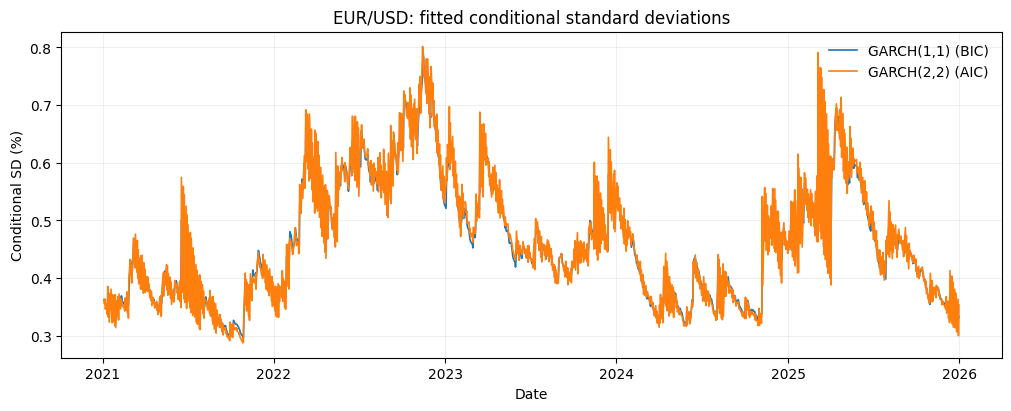

In [13]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for order in sorted(set(selected_variance_orders.values())):
    criteria = ", ".join(c for c, chosen in selected_variance_orders.items() if chosen == order)
    ax.plot(returns.index, variance_fits[order].conditional_volatility,
            linewidth=1.2, label=f"{model_label(order)} ({criteria})")
ax.set(title="EUR/USD: fitted conditional standard deviations", ylabel="Conditional SD (%)", xlabel="Date")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.show()

## Checking the fitted variance dynamics

For each selected model form standardised residuals
$\widehat z_t=\widehat\epsilon_t/\widehat\sigma_t$. Compare the ACF of
their squares with the earlier squared-change ACF, and apply the same
10-lag ARCH diagnostic. The post-fit chi-square calibration is approximate:
residuals and parameters have been estimated and orders selected on these data.
Non-rejection is not proof that every feature of the model is correct.

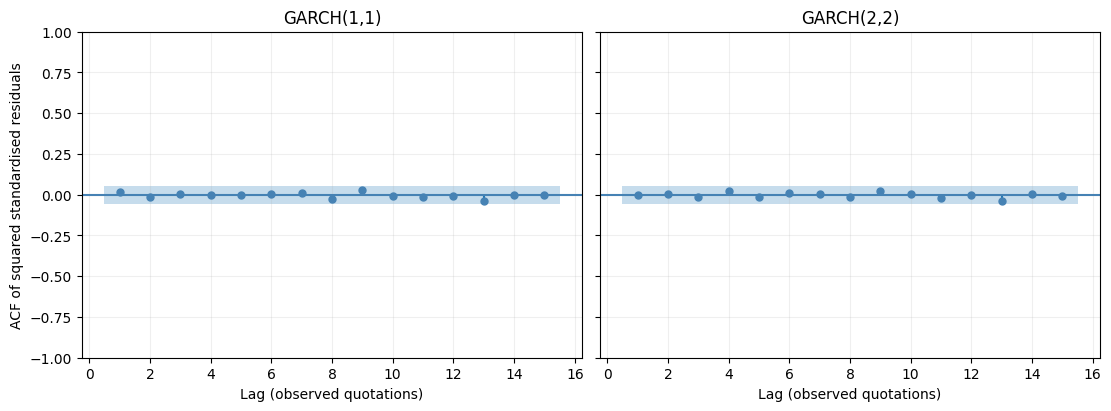

,ARCH LM,p-value
Model,,
"GARCH(1,1)",2.6218,0.989
"GARCH(2,2)",1.8876,0.997


In [14]:
orders = sorted(set(selected_variance_orders.values()))
fig, axes = plt.subplots(1, len(orders), figsize=(11, 4), sharey=True, squeeze=False, constrained_layout=True)
diagnostic_rows = []
for ax, order in zip(axes.ravel(), orders):
    fit = variance_fits[order]
    standardised = fit.std_resid.dropna()
    plot_acf(standardised**2, lags=15, zero=False, alpha=0.05,
             bartlett_confint=False, ax=ax, color="steelblue")
    ax.set(title=model_label(order), xlabel="Lag (observed quotations)")
    ax.grid(alpha=0.2)
    lm, pv, _, _ = het_arch(standardised, nlags=ARCH_TEST_LAGS, ddof=fit.num_params)
    diagnostic_rows.append({"Model": model_label(order), "ARCH LM": lm, "p-value": pv})
axes[0, 0].set_ylabel("ACF of squared standardised residuals")
plt.show()
standardised_diagnostics = pd.DataFrame(diagnostic_rows).set_index("Model")
display(standardised_diagnostics.style.format({"ARCH LM": "{:.4f}", "p-value": "{:.3g}"}))

## Rolling and EWMA comparisons

Compare the AIC-selected GARCH standard deviation with rolling sample standard
deviations over **10, 20 and 50 observations**, and with EWMA for
$\lambda\in\{0.94,0.97\}$:

$$v_t=\lambda v_{t-1}+(1-\lambda)\widehat\epsilon_{t-1}^2.$$

Plot $\sqrt{v_t}$, not $v_t$, to keep all curves in daily percentage units.
Shift rolling estimates by one observation so that the curve labelled $t$
uses changes only through $t-1$, matching the conditional-variance timing.
Initialise EWMA with the same pre-2021 variance used for GARCH. A larger
$\lambda$ puts more weight on earlier information and reacts more slowly.
Unlike a stationary GARCH with positive intercept, this EWMA recursion has no
fixed mean-reverting variance level.

These are historical filters: GARCH parameters and the constant mean are
estimated using the full sample. The comparison is descriptive, not a
real-time forecast evaluation or a comparison with observed true volatility.

C:\Users\gabri\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\plotting\_matplotlib\core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)
C:\Users\gabri\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\plotting\_matplotlib\core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


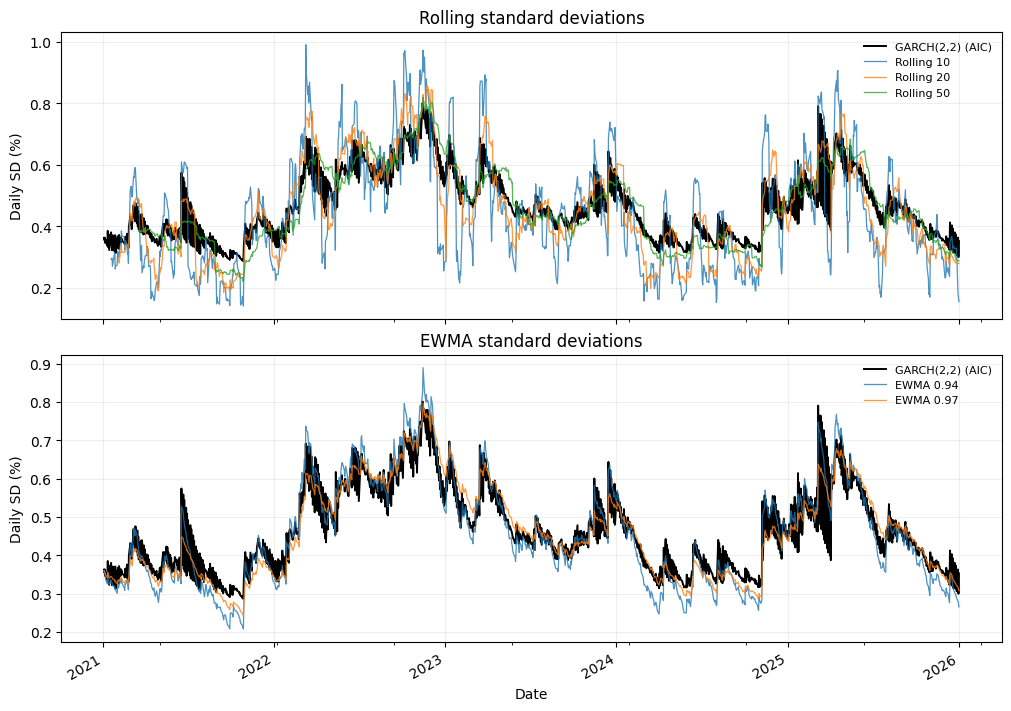

In [15]:
chosen_order = selected_variance_orders["AIC"]
chosen_fit = variance_fits[chosen_order]
rolling_sd = pd.DataFrame({f"Rolling {w}": returns.rolling(w, min_periods=w).std(ddof=1).shift(1)
                           for w in [10, 20, 50]})
epsilon = returns - chosen_fit.params["mu"]
ewma_variance = {}
for lam in [0.94, 0.97]:
    v = np.empty(len(returns))
    v[0] = BACKCAST
    for t in range(1, len(returns)):
        v[t] = lam * v[t - 1] + (1 - lam) * epsilon.iloc[t - 1]**2
    ewma_variance[lam] = pd.Series(v, index=returns.index)
ewma_sd = pd.DataFrame({f"EWMA {lam}": np.sqrt(v) for lam, v in ewma_variance.items()})
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
for ax, comparison, title in zip(axes, [rolling_sd, ewma_sd], ["Rolling standard deviations", "EWMA standard deviations"]):
    ax.plot(returns.index, chosen_fit.conditional_volatility, color="black", linewidth=1.4,
            label=f"{model_label(chosen_order)} (AIC)")
    comparison.plot(ax=ax, linewidth=0.9, alpha=0.8)
    ax.set(title=title, ylabel="Daily SD (%)")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)
axes[-1].set_xlabel("Date")
plt.show()

## Comparing the selected order with a smaller model

Reduce the AIC-selected $(p,q)$ to $(\max(0,p-1),\max(0,q-1))$.
Here this compares **GARCH(2,2) with GARCH(1,1)**. The likelihood-ratio
statistic is $LR=2(\ell_U-\ell_R)$, but a standard chi-square p-value is
not generally justified: variance coefficients are nonnegative, so setting
them to zero places the null on a parameter boundary.

Use a **Gaussian parametric bootstrap under the fitted restricted model**.
Simulate 199 samples, refit both orders in each and compare their LR statistics
with the observed value. The Monte Carlo p-value uses the plus-one correction.
The reported decision uses 5%, but the reference is approximate and treats
the observed orders as fixed. It does not account for choosing the orders on
these same data or protect against a misspecified innovation distribution.
Report its Monte Carlo standard error rather than interpreting small numerical
differences around 5% as decisive. Initialisation and refitting are repeated
for each simulated sample.

In [16]:
BOOTSTRAP_REPLICATIONS = 199
BOOTSTRAP_SEED = 20261015
p_u, q_u = chosen_order
restricted_order = (max(0, p_u - 1), max(0, q_u - 1))
# With no shock lags, the stationary restricted variance is constant.
if restricted_order[0] == 0:
    restricted_order = (0, 0)
restricted_fit = variance_fits[restricted_order]

def nested_start(restricted, order):
    p, q = order
    omega = restricted.params.get("omega", restricted.params.get("sigma2"))
    return np.array([restricted.params["mu"], omega]
                    + [restricted.params.get(f"alpha[{i}]", 0.0) for i in range(1, p + 1)]
                    + [restricted.params.get(f"beta[{j}]", 0.0) for j in range(1, q + 1)])

def fit_unrestricted(values, restricted, initial_variance):
    attempts = []
    for start in [None, nested_start(restricted, chosen_order)]:
        try:
            attempts.append(fit_variance_model(values, chosen_order, initial_variance, start))
        except RuntimeError:
            pass
    if not attempts:
        raise RuntimeError("Both unrestricted optimisation starts failed.")
    result = max(attempts, key=lambda fit: fit.loglikelihood)
    if result.loglikelihood < restricted.loglikelihood - 1e-5:
        raise RuntimeError("Unrestricted likelihood is below its nested restriction.")
    return result

observed_unrestricted = fit_unrestricted(returns, restricted_fit, BACKCAST)
observed_lr = max(0.0, 2 * (observed_unrestricted.loglikelihood - restricted_fit.loglikelihood))
simulation_model = arch_model(None, mean="Constant", vol="Constant" if restricted_order[0] == 0 else "GARCH",
                                           p=max(1, restricted_order[0]), q=restricted_order[1], dist="normal", rescale=False)
simulation_model.distribution = Normal(seed=BOOTSTRAP_SEED)
bootstrap_lr, failed_attempts = [], 0
while len(bootstrap_lr) < BOOTSTRAP_REPLICATIONS:
    simulated = simulation_model.simulate(restricted_fit.params, nobs=len(returns) + PRE_SAMPLE_LENGTH, burn=500)["data"]
    simulated_backcast = float(simulated.iloc[:PRE_SAMPLE_LENGTH].var(ddof=0))
    simulated_sample = simulated.iloc[PRE_SAMPLE_LENGTH:].reset_index(drop=True)
    try:
        restricted = fit_variance_model(simulated_sample, restricted_order, simulated_backcast)
        unrestricted = fit_unrestricted(simulated_sample, restricted, simulated_backcast)
        bootstrap_lr.append(max(0.0, 2 * (unrestricted.loglikelihood - restricted.loglikelihood)))
    except RuntimeError:
        failed_attempts += 1
        if failed_attempts > 20:
            raise RuntimeError("Too many failed bootstrap optimisations: inspect the models.")
bootstrap_p = (1 + np.count_nonzero(np.asarray(bootstrap_lr) >= observed_lr)) / (BOOTSTRAP_REPLICATIONS + 1)
bootstrap_mcse = np.sqrt(bootstrap_p * (1 - bootstrap_p) / (BOOTSTRAP_REPLICATIONS + 1))
specification_comparison = pd.DataFrame({"LR statistic": [observed_lr], "Bootstrap p-value": [bootstrap_p],
    "Monte Carlo SE": [bootstrap_mcse], "Successful replications": [len(bootstrap_lr)],
    "Failed attempts": [failed_attempts],
    "Decision at 5%": ["Reject smaller model" if bootstrap_p < 0.05 else "Do not reject smaller model"]},
    index=[f"{model_label(chosen_order)} versus {model_label(restricted_order)}"])
display(specification_comparison.round(4))

,LR statistic,Bootstrap p-value,Monte Carlo SE,Successful replications,Failed attempts,Decision at 5%
"GARCH(2,2) versus GARCH(1,1)",9.1458,0.01,0.007,199,0,Reject smaller model


## One- and two-step volatility forecasts

From the final observation, **31 December 2025**, compute forecasts of
conditional variance for the next one and two **observed quotations** and take
their square roots. These are historical-origin model forecasts, not prediction
intervals or a verified out-of-sample exercise.

For GARCH(1,1), the first forecast uses the final realised squared residual and
filtered variance. Subsequent forecasts replace future squared shocks by their
conditional expectations. Higher-order models retain their additional lag
structure, so adjustment need not be monotone at every horizon. Both estimated
parameter and order uncertainty are omitted from these point forecasts.

In [17]:
forecast_rows = []
variance_forecasts = {}
for order in sorted(set(selected_variance_orders.values())):
    fit = variance_fits[order]
    future_variance = fit.forecast(horizon=2, method="analytic", reindex=False).residual_variance.iloc[-1]
    variance_forecasts[order] = future_variance.to_numpy()
    criteria = ", ".join(c for c, selected in selected_variance_orders.items() if selected == order)
    forecast_rows.append({"Model": model_label(order), "Selected by": criteria,
                          "h=1 SD (%)": np.sqrt(future_variance.iloc[0]),
                          "h=2 SD (%)": np.sqrt(future_variance.iloc[1])})
volatility_forecasts = pd.DataFrame(forecast_rows).set_index("Model")
display(volatility_forecasts.round(4))

,Selected by,h=1 SD (%),h=2 SD (%)
Model,,,
"GARCH(1,1)",BIC,0.3300,0.3322
"GARCH(2,2)",AIC,0.2994,0.3519
